In [1]:
import os
import h5py
import lmdb
import pickle
import numpy as np
import matplotlib.pyplot as plt

datasets_settings_test = {
    'dw': {
        'data_path': '/p/project1/hai_dm4eo/liu_ch/data/SSL4EO-S2/downstream_lmdb_small_remove/dw_test_lmdb',
        'mode': 's2',
        'n_channels': 13,
    },

    'openearthmap': {
        'data_path': '/p/project1/hai_ws4eo/liu_ch/data/WeakFT/exact/openearthmap_val.lmdb',
    },
}

# DW

ts_acc (1350, 10)
ts_acc_aux (1350, 10)
ts_acc_pred (1350, 10)
ts_acc_pred_ano (1350, 10)
ts_acc_pred_aux (1350, 10)
ts_acc_pred_aux_ano (1350, 10)
ts_exist (1350, 10)
ts_exist_aux (1350, 10)
ts_iou (1350, 10)
ts_iou_aux (1350, 10)
ts_iou_pred (1350, 10)
ts_iou_pred_ano (1350, 10)
ts_iou_pred_aux (1350, 10)
ts_iou_pred_aux_ano (1350, 10)
ts_masks (1350, 256, 256)
ts_masks_aux (1350, 256, 256)
y_exist (1350, 10)


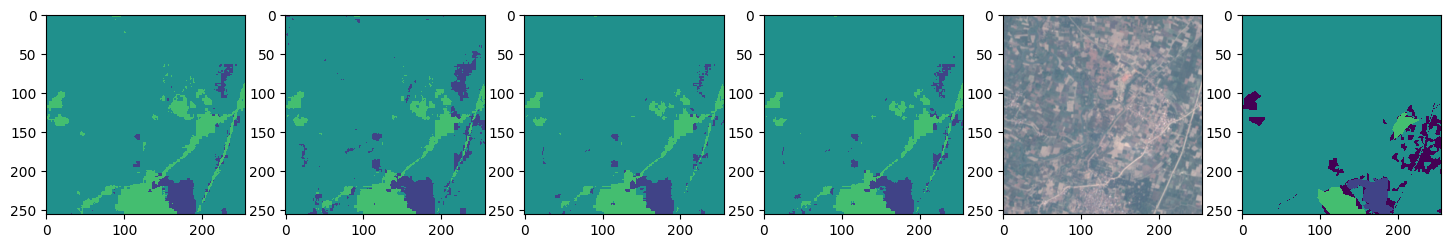

In [6]:
dataset_name = 'dw'
pdir = f'/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage/FT_dofab_aux_exact_max15000_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6/predictions_{dataset_name}'
index = 0

# gt & img
fp_test = datasets_settings_test[dataset_name]['data_path']
with lmdb.open(fp_test, readonly=True).begin(write=False) as txn:
    key_lbl = f'dw_{index}'
    data_lbl = txn.get(key_lbl.encode())
    lbl_bytes, lbl_shape, lbl_fid = pickle.loads(data_lbl)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape).copy()
    # image
    key_s = f's2_{index}'
    data_s = txn.get(key_s.encode())
    img_s, shape_s, fid_s = pickle.loads(data_s)
    img = np.frombuffer(img_s, dtype=np.uint16).reshape(shape_s)[[3,2,1]].astype(np.float32)
    img = img/img.max()

# illustration
plt.figure(figsize=(18, 3))
for ei, ep in enumerate([49, 59, 69, 79]):
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        if ei == 0: 
            for k in f.keys(): print(k, f[k].shape) 
        pred = f['ts_masks'][index]
    plt.subplot(1, 6, ei+1)
    plt.imshow(pred+1, interpolation='none', vmin=0, vmax=10)

plt.subplot(165)
plt.imshow(img.transpose(1,2,0))
plt.subplot(166)
plt.imshow(lbl, interpolation='none', vmin=0, vmax=10)

In [7]:
m = 'acc'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)])
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)])
    # print('')
    # for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
    #     vs[k] = abs(v-ts).mean(axis=0)
    #     print(f'{k:12s}', [f'{v:02f}' for v in vs[k]])

EP=49
acc          ['0.744826', '0.638368', '0.779266', '0.767812', '0.723185', '0.475499', '0.608396', '0.619975', '0.915776', '0.916574']
pred         ['0.759766', '0.703613', '0.937988', '0.838379', '0.756836', '0.693359', '0.567871', '0.771973', '0.944336', '0.937500']
pred_aux     ['0.772949', '0.726562', '0.900879', '0.902344', '0.748535', '0.758301', '0.590820', '0.735840', '0.958496', '0.958984']
pred_ano     ['0.773438', '0.707031', '0.876465', '0.807129', '0.757324', '0.656250', '0.593750', '0.708984', '0.934082', '0.944824']
pred_aux_ano ['0.815430', '0.732422', '0.900391', '0.886230', '0.789551', '0.663574', '0.633789', '0.809570', '0.968262', '0.967285']
EP=59
acc          ['0.794973', '0.654204', '0.805902', '0.857271', '0.754624', '0.512787', '0.639025', '0.582674', '0.930041', '0.946965']
pred         ['0.788574', '0.712402', '0.933105', '0.873047', '0.758789', '0.717773', '0.583984', '0.696289', '0.949219', '0.951172']
pred_aux     ['0.739258', '0.750488', '0.842285', 

In [8]:
m = 'iou'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)], np.mean(ts))
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)], np.mean(v))
    print('')
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        vs[k] = abs(v-ts).mean(axis=0)
        print(f'{k:12s}', [f'{v:02f}' for v in vs[k]])

EP=49
iou          ['0.635238', '0.411763', '0.387287', '0.681403', '0.546905', '0.249280', '0.539410', '0.361058', '0.904711', '0.911150'] 0.56282055
pred         ['0.677246', '0.402832', '0.628906', '0.725098', '0.612793', '0.359131', '0.520996', '0.379150', '0.920410', '0.931152'] 0.6157
pred_aux     ['0.711914', '0.467529', '0.587402', '0.829590', '0.590332', '0.450684', '0.562988', '0.430176', '0.954590', '0.950684'] 0.6533
pred_ano     ['0.303223', '0.328369', '0.046326', '0.030533', '0.243164', '0.180664', '0.230835', '0.083801', '0.027588', '0.028000'] 0.1503
pred_aux_ano ['0.292969', '0.292236', '0.050842', '0.021286', '0.238525', '0.191040', '0.240112', '0.109619', '0.024551', '0.025421'] 0.1487

pred         ['0.172200', '0.217939', '0.376424', '0.161389', '0.191432', '0.255414', '0.124775', '0.244323', '0.043596', '0.038314']
pred_aux     ['0.191970', '0.240358', '0.367269', '0.209329', '0.215442', '0.329349', '0.152333', '0.284608', '0.066682', '0.064483']
pred_ano     ['0

In [13]:
# all the gt labels 
envt = lmdb.open(fp_test, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
lbls = []
with envt.begin(write=False) as txn:
    for i in range(1350):
        key_lbl = f'dw_{i}'
        data_lbl = txn.get(key_lbl.encode())
        lbl_bytes, lbl_shape, lbl_fid = pickle.loads(data_lbl)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape).copy()
        lbl.setflags(write=True)
        lbls.append(lbl)

lbls = np.array(lbls)
print(lbls.shape)

(1350, 256, 256)


In [8]:
def calculate_iou(pred, gt, n_classes):
    ious = []
    for i in range(1,n_classes+1):
        pred_ = (pred == i).astype(float)   
        gt_ = (gt == i).astype(float)
        intersection = np.sum(pred_ * gt_)
        union = np.sum(pred_) + np.sum(gt_) - intersection
        iou = intersection / union
        ious.append(iou)
    return ious

In [ ]:
ious_new = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        masks = f[f'ts_masks'][()] 
        masks_aux = f[f'ts_masks_aux'][()]

    for m, k in zip([masks, masks_aux],['ts_masks', 'ts_masks_aux']):
        m += 1
        m[lbls==0] = 0
        ious_10 = calculate_iou(m, lbls, n_classes=10)
        ious_9  = calculate_iou(m, lbls, n_classes=9)
        ious_new[f'{ep}-{k}-9'] = ious_9 
        ious_new[f'{ep}-{k}-10'] = ious_10

ious_new

In [15]:
for k in ious_new.keys():
    ious_new[k] += [np.mean(ious_new[k])]
    print(f'{k:20s}', [f'{v:02f}' for v in ious_new[k]])

49-ts_masks-9        ['0.889770', '0.739465', '0.251535', '0.464660', '0.771952', '0.440662', '0.796638', '0.432964', '0.779317', '0.618551']
49-ts_masks-10       ['0.889770', '0.739465', '0.251535', '0.464660', '0.771952', '0.440662', '0.796638', '0.432964', '0.779317', '0.412528', '0.597949']
49-ts_masks_aux-9    ['0.883698', '0.716039', '0.241018', '0.488620', '0.765913', '0.411190', '0.801039', '0.427896', '0.830180', '0.618399']
49-ts_masks_aux-10   ['0.883698', '0.716039', '0.241018', '0.488620', '0.765913', '0.411190', '0.801039', '0.427896', '0.830180', '0.449679', '0.601527']
59-ts_masks-9        ['0.880315', '0.720698', '0.266640', '0.491653', '0.776549', '0.430034', '0.808351', '0.463386', '0.825156', '0.629198']
59-ts_masks-10       ['0.880315', '0.720698', '0.266640', '0.491653', '0.776549', '0.430034', '0.808351', '0.463386', '0.825156', '0.407899', '0.607068']
59-ts_masks_aux-9    ['0.906272', '0.712832', '0.251750', '0.479422', '0.765271', '0.413458', '0.806966', '0.486

# OpenEarthNet

[2 3 4 5 8]


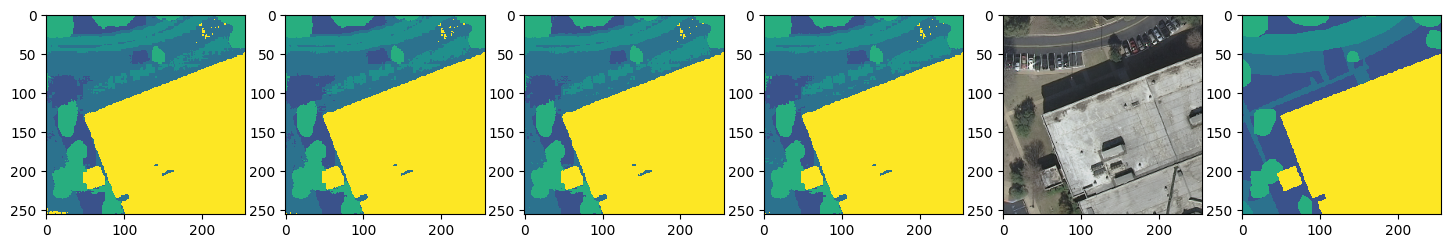

In [16]:
dataset_name = 'openearthmap'
pdir = f'/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/Results_1st_stage/FT_dofab_aux_exact_max15000_deI_mcloss/10F_1D_lr1e4_cos_w5_cos95/seed_42_bs_6/predictions_{dataset_name}'
index = 310
n_cls = 8

# gt & img
fp_test = datasets_settings_test[dataset_name]['data_path']
with lmdb.open(fp_test, readonly=True).begin(write=False) as txn:
    key = str(index)
    data = txn.get(key.encode())
    data_bytes, data_shape, lbl_bytes, lbl_shape, a = pickle.loads(data)
    # print(data_shape, lbl_shape)
    img = np.frombuffer(data_bytes, dtype=np.uint8).reshape(data_shape)
    lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)
    
# illustration
plt.figure(figsize=(18, 3))
for ei, ep in enumerate([49, 59, 69, 79]):
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        # if ei == 0: 
        #     for k in f.keys(): print(k, f[k].shape) 
        pred = f['ts_masks'][index]
    plt.subplot(1, 6, ei+1)
    plt.imshow(pred+1, interpolation='none', vmin=0, vmax=n_cls)

plt.subplot(165)
plt.imshow(img.transpose(1,2,0))
plt.subplot(166)
plt.imshow(lbl, interpolation='none', vmin=0, vmax=n_cls)
print(np.unique(lbl))

In [21]:
m = 'acc'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)], np.mean(ts))
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)], np.mean(v))
    print('')
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        vs[k] = abs(v-ts).mean(axis=0)
        print(f'{k:12s}', [f'{v:02f}' for v in vs[k]], np.mean(vs[k]))

EP=49
acc          ['0.953294', '0.690570', '0.666054', '0.754758', '0.766745', '0.752312', '0.928162', '0.886002'] 0.7997366
pred         ['0.987305', '0.790039', '0.744629', '0.815918', '0.851562', '0.888184', '0.988281', '0.926758'] 0.874
pred_aux     ['0.983887', '0.783203', '0.734375', '0.817871', '0.836914', '0.827148', '0.984375', '0.916992'] 0.8604
pred_ano     ['0.987793', '0.755859', '0.714355', '0.840820', '0.814453', '0.849609', '0.985840', '0.914551'] 0.858
pred_aux_ano ['0.992676', '0.775879', '0.750488', '0.828125', '0.863770', '0.931152', '0.986816', '0.921387'] 0.8813

pred         ['0.039210', '0.193168', '0.177437', '0.160171', '0.141899', '0.178134', '0.068769', '0.076889'] 0.12945956
pred_aux     ['0.041874', '0.197448', '0.181415', '0.163620', '0.145172', '0.185434', '0.070127', '0.082727'] 0.13347712
pred_ano     ['0.036774', '0.176477', '0.154919', '0.154580', '0.126797', '0.121287', '0.067062', '0.076836'] 0.11434142
pred_aux_ano ['0.045214', '0.195797', '0.178

In [22]:
m = 'iou'
vs = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        ts = f[f'ts_{m}'][()]
        pred = f[f'ts_{m}_pred'][()]
        pred_aux = f[f'ts_{m}_pred_aux'][()]
        pred_ano = f[f'ts_{m}_pred_ano'][()]
        pred_aux_ano = f[f'ts_{m}_pred_aux_ano'][()]
    print(f'{m:12s}', [f'{v:02f}' for v in ts.mean(axis=0)], np.mean(ts))
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        print(f'{k:12s}', [f'{v0:02f}' for v0 in v.mean(axis=0)], np.mean(v))
    print('')
    for k, v in zip(['pred', 'pred_aux', 'pred_ano', 'pred_aux_ano'], [pred, pred_aux, pred_ano, pred_aux_ano]):
        vs[k] = abs(v-ts).mean(axis=0)
        print(f'{k:12s}', [f'{v:02f}' for v in vs[k]], np.mean(vs[k]))

EP=49
iou          ['0.919662', '0.452454', '0.465722', '0.587905', '0.612524', '0.691734', '0.844107', '0.780741'] 0.66935617
pred         ['0.949219', '0.478027', '0.451660', '0.598633', '0.648438', '0.768066', '0.876953', '0.807129'] 0.6973
pred_aux     ['0.948242', '0.458252', '0.437256', '0.596191', '0.615234', '0.777832', '0.853516', '0.795898'] 0.6855
pred_ano     ['0.017227', '0.403320', '0.311035', '0.393555', '0.562988', '0.133301', '0.182495', '0.539551'] 0.3179
pred_aux_ano ['0.018600', '0.428223', '0.307129', '0.369873', '0.551758', '0.124817', '0.182007', '0.542480'] 0.3157

pred         ['0.051510', '0.136300', '0.120778', '0.122704', '0.100186', '0.141322', '0.090926', '0.077410'] 0.10514183
pred_aux     ['0.063386', '0.140142', '0.126320', '0.134188', '0.107331', '0.187722', '0.107190', '0.086079'] 0.119044915
pred_ano     ['0.918209', '0.160712', '0.236016', '0.306060', '0.138306', '0.657040', '0.705365', '0.307529'] 0.42865467
pred_aux_ano ['0.919283', '0.171599', '0

In [10]:
# all the gt labels 
envt = lmdb.open(fp_test, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
lbls = []
with envt.begin(write=False) as txn:
    for index in range(4270):
        key = str(index)
        data = txn.get(key.encode())
        data_bytes, data_shape, lbl_bytes, lbl_shape, a = pickle.loads(data)
        lbl = np.frombuffer(lbl_bytes, dtype=np.uint8).reshape(lbl_shape)#.copy()
        # lbl.setflags(write=True)
        lbls.append(lbl)

lbls = np.stack(lbls, axis=0)
print(lbls.shape)

(4270, 256, 256)


In [11]:
np.unique(lbls)

array([0, 1, 2, 3, 4, 5, 6, 7, 8], dtype=uint8)

In [12]:
ious_new = {}
for ei, ep in enumerate([49, 59, 69, 79]):
    print(f'EP={ep}')
    pred_fp = os.path.join(pdir, f'pred_EP{ep}.h5')
    with h5py.File(pred_fp, 'r') as f:
        masks = f[f'ts_masks'][()] 
        masks_aux = f[f'ts_masks_aux'][()]

    for m, k in zip([masks, masks_aux],['ts_masks', 'ts_masks_aux']):
        m += 1
        m[lbls==0] = 0
        ious_ = calculate_iou(m, lbls, n_classes=n_cls)
        ious_new[f'{ep}-{k}'] = ious_

for k in ious_new.keys():
    ious_new[k] += [np.mean(ious_new[k])]
    print(f'{k:20s}', [f'{v:02f}' for v in ious_new[k]])

EP=49
EP=59
EP=69
EP=79
49-ts_masks          ['0.366195', '0.559339', '0.529793', '0.558067', '0.712743', '0.721244', '0.750169', '0.775754', '0.621663']
49-ts_masks_aux      ['0.371055', '0.565107', '0.519410', '0.551284', '0.703704', '0.726615', '0.746079', '0.771742', '0.619374']
59-ts_masks          ['0.378385', '0.565150', '0.522665', '0.570366', '0.711225', '0.735414', '0.745784', '0.779050', '0.626005']
59-ts_masks_aux      ['0.373689', '0.570802', '0.527596', '0.554788', '0.703635', '0.731618', '0.743103', '0.775373', '0.622575']
69-ts_masks          ['0.394210', '0.565709', '0.531039', '0.570881', '0.713529', '0.742082', '0.750437', '0.779999', '0.630986']
69-ts_masks_aux      ['0.381410', '0.568587', '0.526547', '0.560414', '0.709369', '0.740591', '0.748587', '0.775408', '0.626364']
79-ts_masks          ['0.399865', '0.565493', '0.531596', '0.571640', '0.712886', '0.738828', '0.749248', '0.781278', '0.631354']
79-ts_masks_aux      ['0.378614', '0.566160', '0.527751', '0.56373